# 02 · Efecto del aumento de datos en ConvNeXt-Tiny (`Base` vs. `Malignant`)

**Pregunta:** ¿Qué cambia al entrenar ConvNeXt-Tiny con aumento estándar (`Base`) frente a `MalignantScaleAugmentation` (`Malignant`) en esquemas de 2 y 3 clases?

Referencia histórica: [Notebook de Andrés](../02_experimento_seleccion_datasets_y_modelos/Comprobacion_mejor_modelo.ipynb).

## 1. Configuración y datos auditados

Se carga el mismo dataset depurado (`dataset_auditado.csv`) sin fuga de datos entre particiones ni fuentes externas.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from torchvision import transforms as T

_root = Path.cwd().resolve()
if not (_root / "utilidades/utilidades.py").is_file() and (_root.parent / "utilidades/utilidades.py").is_file():
    _root = _root.parent
sys.path.insert(0, str(_root / "utilidades"))
sys.path.insert(0, str(_root / "03_experimento_caracteristicas_retinografias/scripts"))

import utilidades as u
from metricas_retinografias import retinal_mask, thumbnail

ROOT = u.obtener_raiz()
SALIDAS = ROOT / "05_experimento_data_augmentation/resultados"
SALIDAS.mkdir(parents=True, exist_ok=True)
MODELOS = ROOT / "modelos"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

EPOCHS = 20
BATCH_SIZE = 32
REENTRENAR = False

u.fijar_semilla(u.SEED)
df_datos, _ = u.cargar_dataset(ROOT)

train_df = df_datos[df_datos["split"] == "train"].reset_index(drop=True)
val_df = df_datos[df_datos["split"] == "val"].reset_index(drop=True)
eval_sets = {"Moondream · test": df_datos[df_datos["split"] == "test"].reset_index(drop=True)}
for fuente in ("ACRIMA", "RIM-ONE DL", "EyePACS REAL"):
    sub = df_datos[df_datos["coleccion"] == fuente].reset_index(drop=True)
    if len(sub):
        eval_sets[fuente] = sub

print(f"Dispositivo: {DEVICE} | Train={len(train_df)}, Val={len(val_df)}, Test={len(eval_sets['Moondream · test'])}")
display(df_datos.groupby(["coleccion", "split", "clase"]).size().rename("n").reset_index())

Dispositivo: cuda | Train=504, Val=107, Test=95


,coleccion,split,clase,n
0,ACRIMA,externo,glaucoma,395
1,ACRIMA,externo,normal,308
2,EyePACS REAL,externo,glaucoma,100
3,EyePACS REAL,externo,normal,100
4,Moondream Staged,test,advanced,25
5,Moondream Staged,test,early,21
6,Moondream Staged,test,normal,49
7,Moondream Staged,train,advanced,125
8,Moondream Staged,train,early,115
9,Moondream Staged,train,normal,264


## 2. Comprobación visual y fotométrica (`Base` vs. `Malignant`)

`Malignant` se aplica **solo en entrenamiento** (`zoom-out` con fondo sintético, `zoom-in` aleatorio, volteos y ajuste de gamma/verde). Validación y test usan siempre `Base` (redimensionado simple a $224\times 224$).

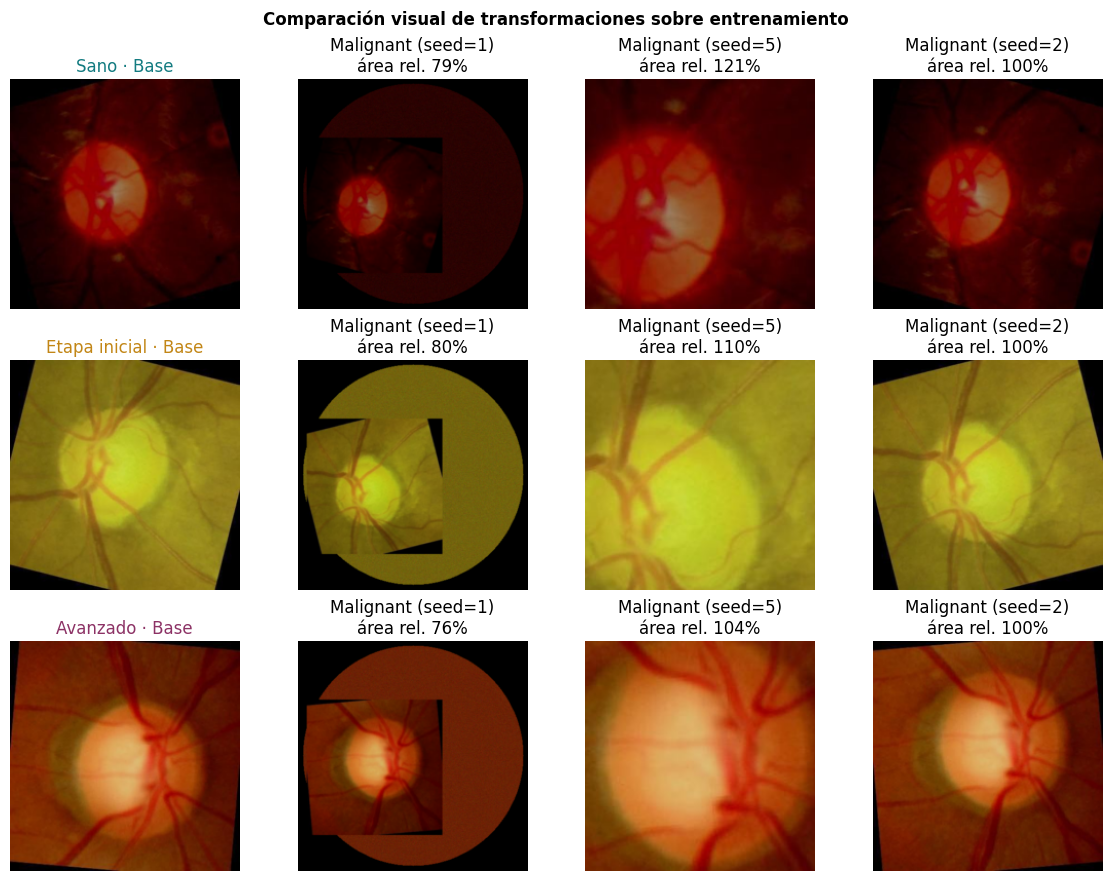

R       G      B  casi_negro_pct
cohorte          clase    brazo                                           
ACRIMA           glaucoma Base       203.14   93.63  19.77            0.11
                          Malignant  182.68   86.06  19.36           10.96
                 normal   Base       172.77  100.94  26.61            0.09
                          Malignant  158.67   94.54  27.24           11.84
EyePACS REAL     glaucoma Base        87.91   57.55  39.75           25.04
                          Malignant   80.25   51.87  34.80           23.40
                 normal   Base        88.28   55.07  32.59           24.05
                          Malignant   84.70   52.55  29.53           21.02
Moondream Staged advanced Base       173.75  115.41  53.67            2.94
                          Malignant  159.38  106.26  47.98           12.72
                 early    Base       161.69  107.33  53.95            3.17
                          Malignant  150.91  105.62  50.65           12.86
                 normal   Base       161.05  108.17  74.36            4.15
                          Malignant  142.85   94.64  63.53           16.70
RIM-ONE DL       glaucoma Base       150.38   69.16  37.94            0.00
                          Malignant  136.43   64.26  34.98           12.78
                 normal   Base       148.15   64.10  33.49            0.00
                          Malignant  137.02   60.45  31.50           12.01

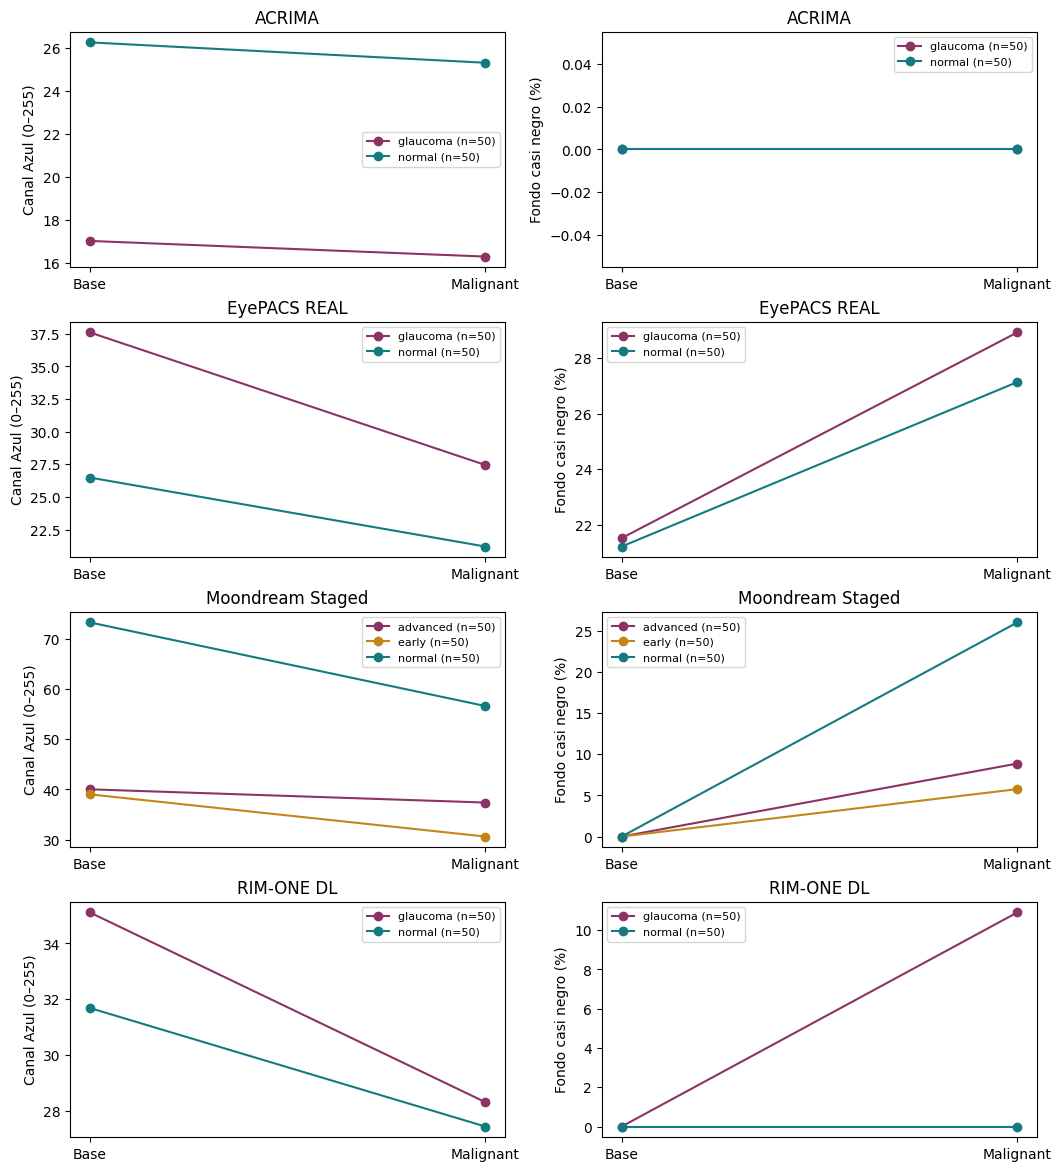

In [2]:
tf_base = T.Resize((224, 224))
tf_malignant = T.Compose([
    u.MalignantScaleAugmentation(output_size=(224, 224)),
    T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(),
])

def porc_negro_y_rgb(img_pil):
    arr = np.asarray(img_pil)
    r, g, b = arr.mean(axis=(0, 1))
    negro = 100.0 * (arr.max(axis=2) <= 10).mean()
    return {"R": r, "G": g, "B": b, "casi_negro_pct": negro}

def retencion_campo(img_orig, img_aug):
    """Estima qué fracción del disco/campo retiniano visible conserva una vista."""
    m0, cat0 = retinal_mask(thumbnail(np.asarray(img_orig)))
    m1, cat1 = retinal_mask(thumbnail(np.asarray(img_aug)))
    if m0 is None or m1 is None or cat0 == "sin_componente_visible" or cat1 == "sin_componente_visible":
        return np.nan
    return 100.0 * m1.mean() / max(m0.mean(), 1e-6)

# Mosaico con 1 ejemplo por clase
ejemplos = train_df.groupby("clase", sort=False).head(1).sort_values("y3")
fig, axes = plt.subplots(len(ejemplos), 4, figsize=(11.5, 2.9 * len(ejemplos)), layout="constrained")
for fila_ax, row in zip(axes, ejemplos.itertuples()):
    img = u.leer_rgb(ROOT, row.id)
    fila_ax[0].imshow(tf_base(img))
    fila_ax[0].set_title(f"{u.CLASES_3[int(row.y3)]} · Base", color=u.COLORES_CLASE[int(row.y3)])
    for ax, sem in zip(fila_ax[1:], (1, 5, 2)):
        u.fijar_semilla(sem)
        aug = tf_malignant(img)
        ax.imshow(aug)
        ret = retencion_campo(img, aug)
        ax.set_title(f"Malignant (seed={sem})" + (f"\nárea rel. {ret:.0f}%" if np.isfinite(ret) else ""))
    for ax in fila_ax:
        ax.axis("off")
fig.suptitle("Comparación visual de transformaciones sobre entrenamiento", fontweight="bold")
plt.show()

# Señales pareadas sobre una muestra estratificada (hasta 50 por cohorte y clase)
muestra_df = df_datos[df_datos["split"].isin(["train", "externo"])]
muestra_df = muestra_df.groupby(["coleccion", "clase"], sort=False).apply(
    lambda g: g.sample(n=min(50, len(g)), random_state=u.SEED), include_groups=False
).reset_index(level=[0, 1]).reset_index(drop=True)

senales = []
for i, row in enumerate(muestra_df.itertuples()):
    img = u.leer_rgb(ROOT, row.id)
    u.fijar_semilla(u.SEED + i)
    for brazo, vista in (("Base", tf_base(img)), ("Malignant", tf_malignant(img))):
        senales.append({"id": row.id, "cohorte": row.coleccion, "clase": row.clase, "brazo": brazo, **porc_negro_y_rgb(vista)})

visual_df = pd.DataFrame(senales)
visual_df.to_csv(SALIDAS / "02_senales_visuales_pareadas.csv", index=False)
display(visual_df.groupby(["cohorte", "clase", "brazo"])[["R", "G", "B", "casi_negro_pct"]].mean().round(2))

cohortes_vis = visual_df["cohorte"].unique()
fig, axes = plt.subplots(len(cohortes_vis), 2, figsize=(10.5, 2.9 * len(cohortes_vis)), squeeze=False, layout="constrained")
for (src, grp), pair_ax in zip(visual_df.groupby("cohorte"), axes):
    for ax, met, ylab in zip(pair_ax, ["B", "casi_negro_pct"], ["Canal Azul (0–255)", "Fondo casi negro (%)"]):
        for cl, sub in grp.groupby("clase"):
            med = sub.groupby("brazo")[met].median().reindex(["Base", "Malignant"])
            ax.plot(med.index, med.values, marker="o", color=u.COLORES_CLASE[u.ENC_3.get(cl, 2)],
                    label=f"{cl} (n={len(sub)//2})")
        ax.set(title=src, ylabel=ylab)
        ax.legend(fontsize=8)
plt.show()

## 3. Entrenamiento factorial ($2 \text{ y } 3 \text{ clases} \times \text{Base y Malignant}$)

Los 4 modelos entrenan con el mismo protocolo (`AdamW`, warmup de 1 época + 20 épocas con `CosineAnnealingLR`) y calibran su umbral $\tau$ en validación (especificidad $\ge 0.95$).

Modelo cargado: fabian_convnext_tiny_2c_base.pth (mejor época 2)


Modelo cargado: fabian_convnext_tiny_2c_malignant.pth (mejor época 9)


Modelo cargado: fabian_convnext_tiny_3c_base.pth (mejor época 12)


Modelo cargado: fabian_convnext_tiny_3c_malignant.pth (mejor época 12)


,clases,brazo,mejor_epoca,tau,espec_val,tau_bin,espec_bin_val
0,2,Base,2,0.92,0.981,0.92,0.981
1,2,Malignant,9,0.95,0.962,0.95,0.962
2,3,Base,12,0.81,0.887,0.81,0.887
3,3,Malignant,12,0.94,0.962,0.94,0.962


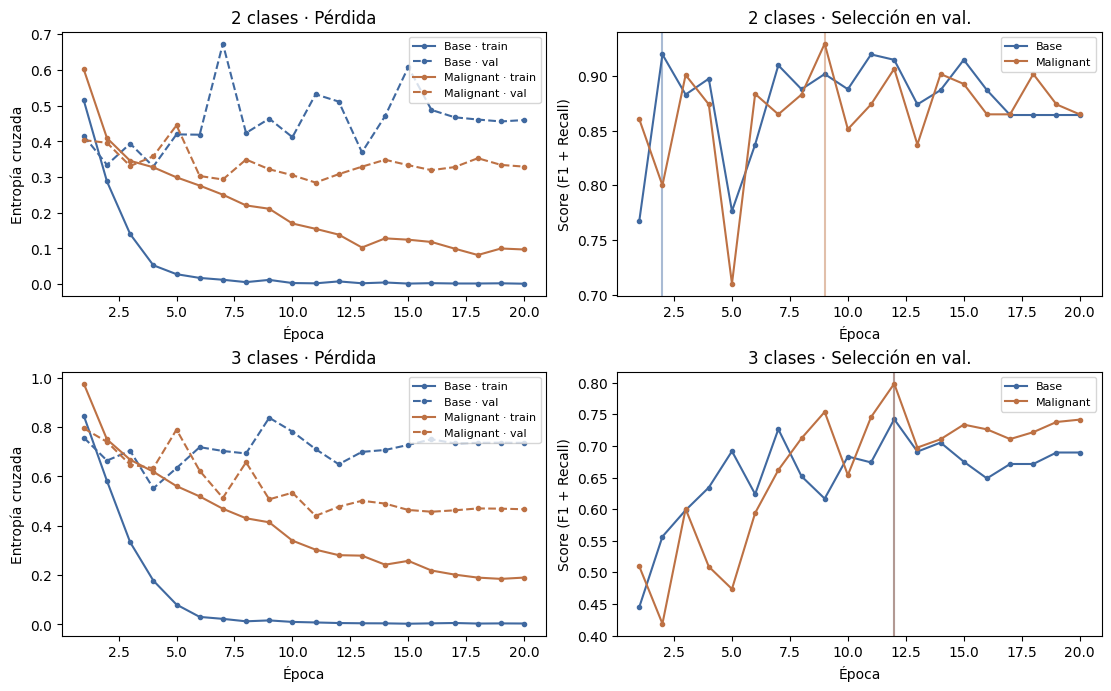

In [3]:
to_tensor = T.Compose([T.ToTensor(), T.Normalize(u.MEAN, u.STD)])
tf_eval = T.Compose([tf_base, to_tensor])
recetas = {"Base": tf_eval, "Malignant": T.Compose([tf_malignant, to_tensor])}

corridas = {}
for n_clases in (2, 3):
    for brazo, tf_tr in recetas.items():
        ruta_pth = MODELOS / f"fabian_convnext_tiny_{n_clases}c_{brazo.lower()}.pth"
        res = u.entrenar_o_cargar(
            train_df, val_df, ROOT, n_clases, tf_tr, tf_eval,
            ruta_modelo=ruta_pth, epochs=EPOCHS, batch_size=BATCH_SIZE,
            device=DEVICE, reentrenar=REENTRENAR,
        )
        y_val = val_df[f"y{n_clases}"].to_numpy(int)
        tau, espec = u.calibrar_umbral(y_val, res["val_prob"], n_clases)
        tau2, espec2 = (u.calibrar_umbral(val_df["y2"].to_numpy(int), res["val_prob"], 2)
                        if n_clases == 3 else (tau, espec))

        probs = {}
        for fuente, df_eval in eval_sets.items():
            nivel = n_clases if fuente == "Moondream · test" else 2
            loader = u.crear_loader(df_eval, ROOT, nivel, tf_eval, batch_size=BATCH_SIZE, device=DEVICE)
            _, probs[fuente] = u.predecir(res["model"], loader, DEVICE, calcular_loss=False)

        corridas[n_clases, brazo] = {
            "hist": res["hist"], "epoca": res["epoca"],
            "tau": tau, "espec": espec, "tau2": tau2, "espec2": espec2, "probs": probs,
        }
        del res["model"]
        if DEVICE == "cuda":
            torch.cuda.empty_cache()

tabla_cal = [
    {"clases": nc, "brazo": br, "mejor_epoca": r["epoca"], "tau": r["tau"], "espec_val": r["espec"],
     "tau_bin": r["tau2"], "espec_bin_val": r["espec2"]}
    for (nc, br), r in corridas.items()
]
display(pd.DataFrame(tabla_cal).round(3))

# Curvas de aprendizaje
fig, axes = plt.subplots(2, 2, figsize=(11, 6.8), layout="constrained")
for nc in (2, 3):
    for color, br in zip(u.COLORES_FUENTE, ("Base", "Malignant")):
        r = corridas[nc, br]
        h = r["hist"]
        axes[nc - 2, 0].plot(h["epoca"], h["train"], color=color, marker=".", label=f"{br} · train")
        axes[nc - 2, 0].plot(h["epoca"], h["val"], "--", color=color, marker=".", label=f"{br} · val")
        axes[nc - 2, 1].plot(h["epoca"], h["score"], color=color, marker=".", label=br)
        axes[nc - 2, 1].axvline(r["epoca"], color=color, alpha=0.45)
    axes[nc - 2, 0].set(title=f"{nc} clases · Pérdida", xlabel="Época", ylabel="Entropía cruzada")
    axes[nc - 2, 1].set(title=f"{nc} clases · Selección en val.", xlabel="Época", ylabel="Score (F1 + Recall)")
    axes[nc - 2, 0].legend(fontsize=8)
    axes[nc - 2, 1].legend(fontsize=8)
plt.show()

## 4. Evaluación y efecto pareado (`Malignant − Base`)

- `2→2`: entrenado binario evaluado en binario.
- `3→2`: entrenado trinario proyectado a binario ($P(\text{Inicial})+P(\text{Avanzado})$).
- `3→3`: estadio trinario en Moondream `test` ($n = 95$).

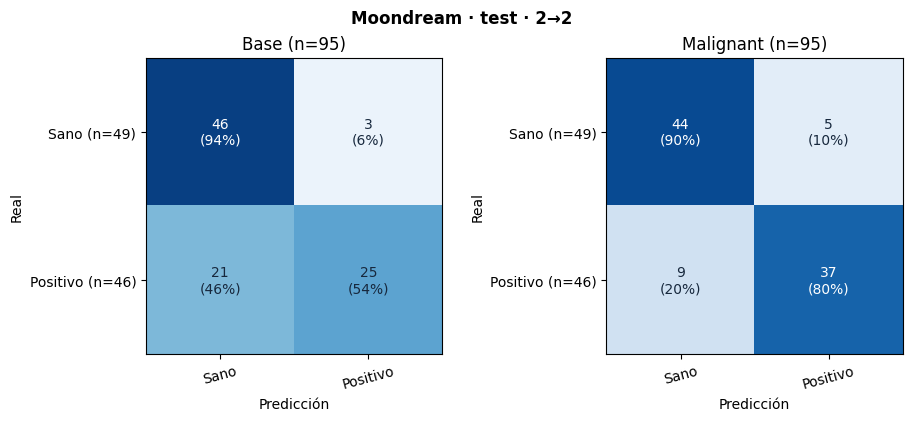

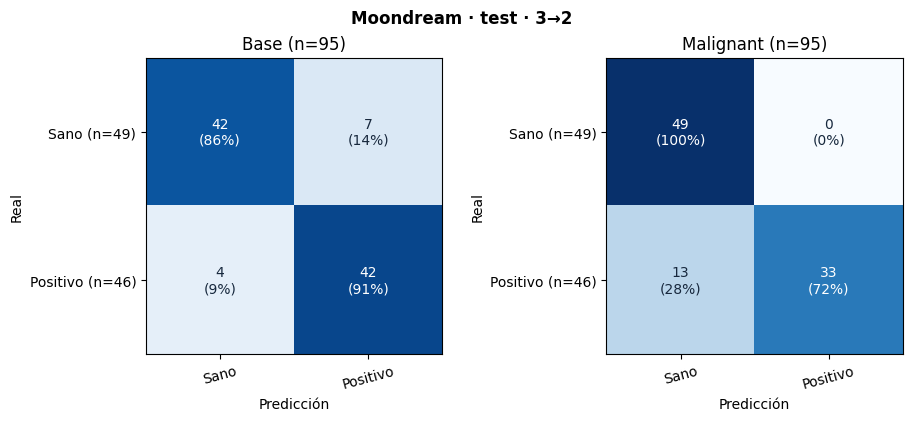

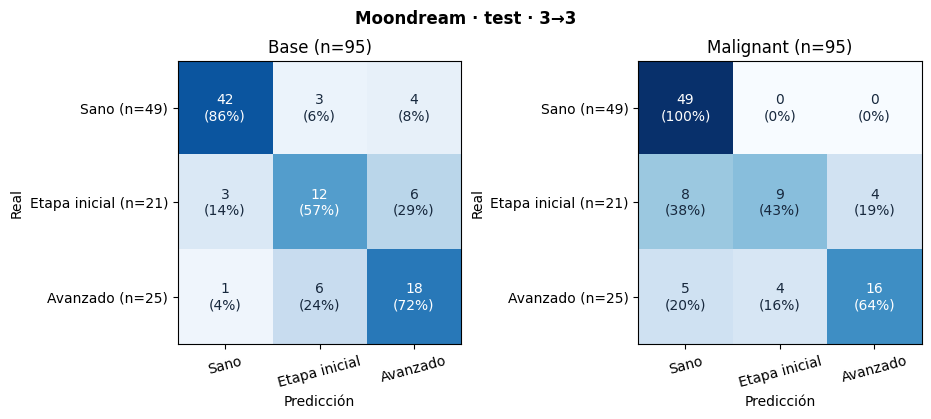

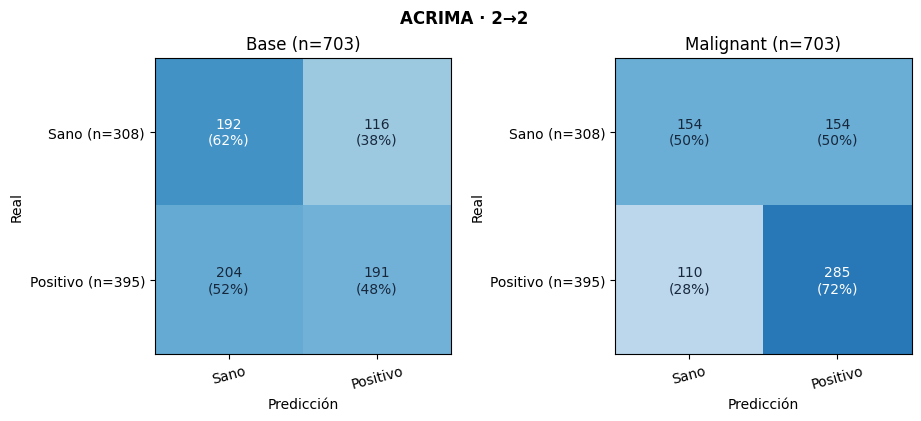

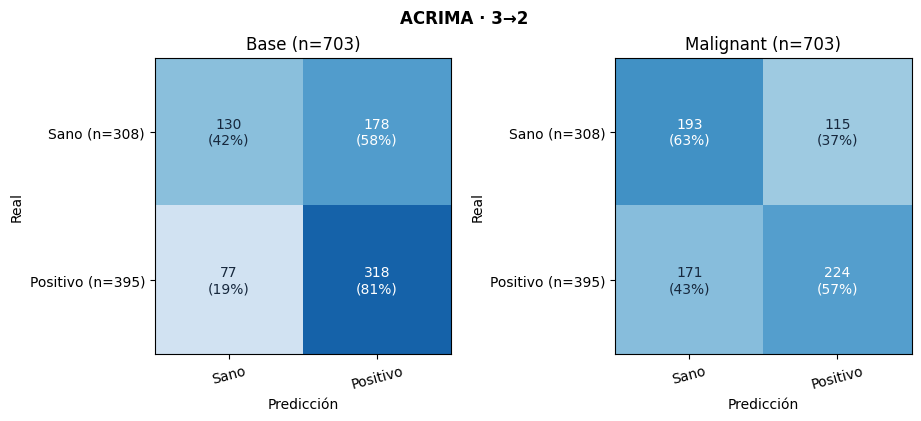

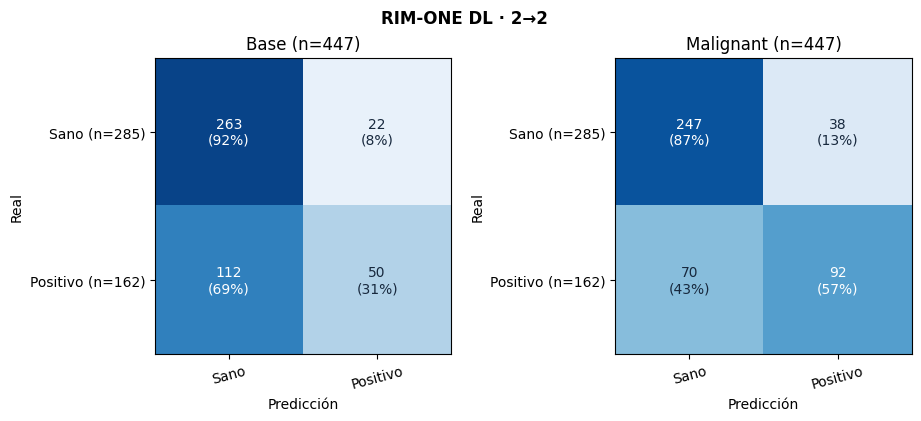

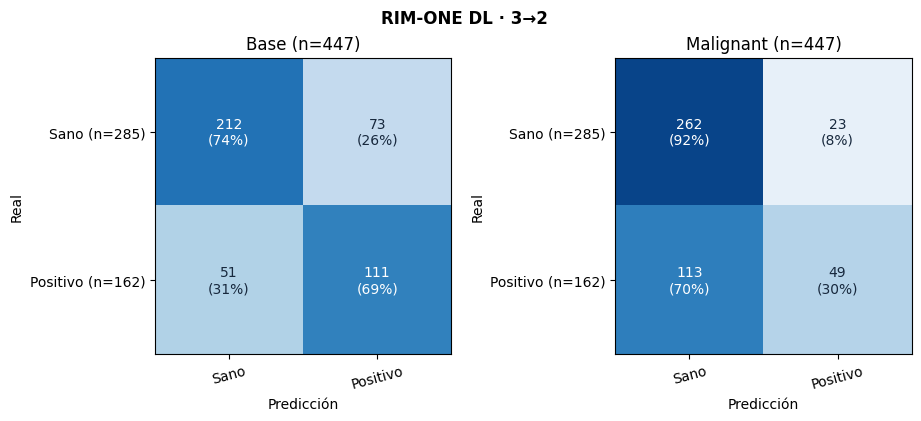

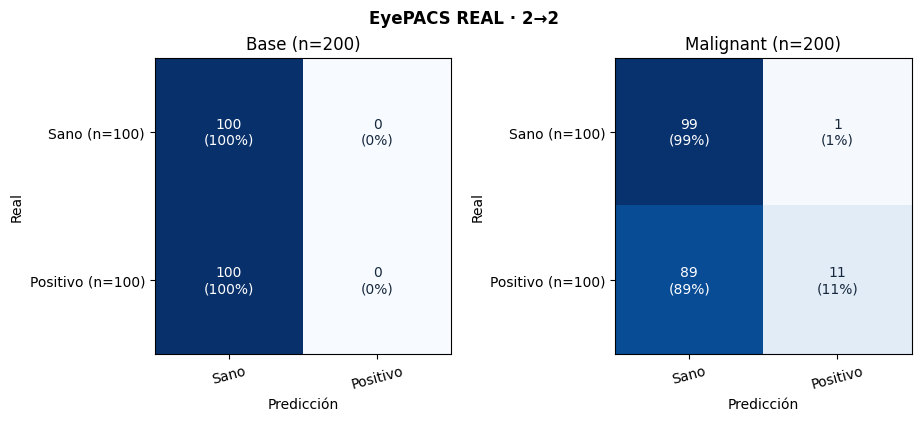

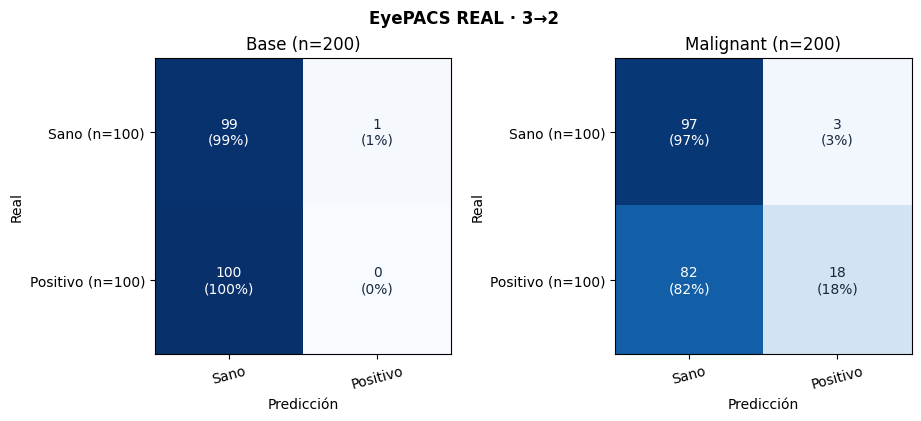

,tarea,nivel,cohorte,brazo,n,F1 macro,exactitud,sensibilidad,especificidad,TFP,...,FP,FN,AUROC,AP,recall inicial,recall avanzado,QWK,FN inicial,FN avanzado,errores sano ↔ avanzado
0,2,2,Moondream · test,Base,95,0.734,0.747,0.543,0.939,0.061,...,3.0,21.0,0.921,0.896,NaN,NaN,NaN,NaN,NaN,NaN
1,2,2,Moondream · test,Malignant,95,0.852,0.853,0.804,0.898,0.102,...,5.0,9.0,0.944,0.930,NaN,NaN,NaN,NaN,NaN,NaN
2,3,2,Moondream · test,Base,95,0.884,0.884,0.913,0.857,0.143,...,7.0,4.0,0.948,0.937,NaN,NaN,NaN,NaN,NaN,NaN
3,3,2,Moondream · test,Malignant,95,0.859,0.863,0.717,1.000,0.000,...,0.0,13.0,0.969,0.968,NaN,NaN,NaN,NaN,NaN,NaN
4,3,3,Moondream · test,Base,95,0.712,0.758,0.913,0.857,0.143,...,NaN,NaN,NaN,NaN,0.571,0.72,0.726,3.0,1.0,5.0
5,3,3,Moondream · test,Malignant,95,0.708,0.779,0.717,1.000,0.000,...,NaN,NaN,NaN,NaN,0.429,0.64,0.733,8.0,5.0,5.0
6,2,2,ACRIMA,Base,703,0.545,0.545,0.484,0.623,0.377,...,116.0,204.0,0.593,0.661,NaN,NaN,NaN,NaN,NaN,NaN
7,2,2,ACRIMA,Malignant,703,0.611,0.624,0.722,0.500,0.500,...,154.0,110.0,0.656,0.688,NaN,NaN,NaN,NaN,NaN,NaN
8,3,2,ACRIMA,Base,703,0.609,0.637,0.805,0.422,0.578,...,178.0,77.0,0.692,0.744,NaN,NaN,NaN,NaN,NaN,NaN
9,3,2,ACRIMA,Malignant,703,0.592,0.593,0.567,0.627,0.373,...,115.0,171.0,0.641,0.692,NaN,NaN,NaN,NaN,NaN,NaN


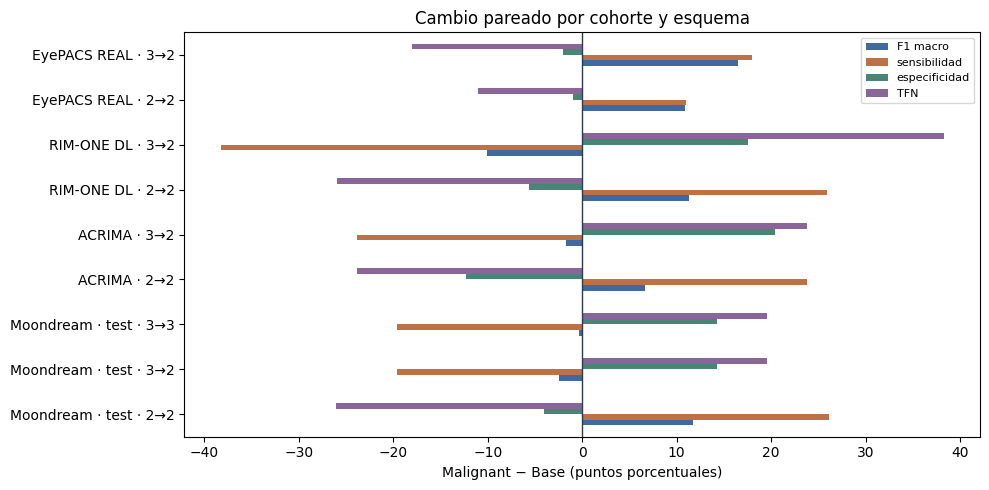

Diferencia en conteo de errores (Malignant − Base):


FN  FN inicial  FN avanzado  \
tarea nivel cohorte                                           
2     2     Moondream · test -12.0         NaN          NaN   
3     2     Moondream · test   9.0         NaN          NaN   
      3     Moondream · test   NaN         5.0          4.0   
2     2     ACRIMA           -94.0         NaN          NaN   
3     2     ACRIMA            94.0         NaN          NaN   
2     2     RIM-ONE DL       -42.0         NaN          NaN   
3     2     RIM-ONE DL        62.0         NaN          NaN   
2     2     EyePACS REAL     -11.0         NaN          NaN   
3     2     EyePACS REAL     -18.0         NaN          NaN   

                              errores sano ↔ avanzado  
tarea nivel cohorte                                    
2     2     Moondream · test                      NaN  
3     2     Moondream · test                      NaN  
      3     Moondream · test                      0.0  
2     2     ACRIMA                                NaN  
3     2     ACRIMA                                NaN  
2     2     RIM-ONE DL                            NaN  
3     2     RIM-ONE DL                            NaN  
2     2     EyePACS REAL                          NaN  
3     2     EyePACS REAL                          NaN

Intervalos de confianza 95% bootstrap para Malignant − Base:


,medida,delta,ic95_inf,ic95_sup,cohorte,tarea,nivel,n
0,F1 macro,0.117,0.037,0.200,Moondream · test,2,2,95
1,sensibilidad,0.261,0.130,0.391,Moondream · test,2,2,95
2,especificidad,-0.041,-0.122,0.041,Moondream · test,2,2,95
3,F1 macro,-0.025,-0.102,0.052,Moondream · test,3,2,95
4,sensibilidad,-0.196,-0.326,-0.087,Moondream · test,3,2,95
5,especificidad,0.143,0.061,0.245,Moondream · test,3,2,95
6,F1 macro,-0.004,-0.111,0.093,Moondream · test,3,3,95
7,sensibilidad,-0.196,-0.304,-0.087,Moondream · test,3,3,95
8,especificidad,0.143,0.061,0.245,Moondream · test,3,3,95
9,F1 macro,0.066,0.034,0.099,ACRIMA,2,2,703


Moondream · test · 2→2 (n=95): Δ F1=+11.7 pp · Δ TFN=-26.1 pp
Moondream · test · 3→2 (n=95): Δ F1=-2.5 pp · Δ TFN=+19.6 pp
Moondream · test · 3→3 (n=95): Δ F1=-0.4 pp · Δ TFN=+19.6 pp
ACRIMA · 2→2 (n=703): Δ F1=+6.6 pp · Δ TFN=-23.8 pp
ACRIMA · 3→2 (n=703): Δ F1=-1.7 pp · Δ TFN=+23.8 pp
RIM-ONE DL · 2→2 (n=447): Δ F1=+11.3 pp · Δ TFN=-25.9 pp
RIM-ONE DL · 3→2 (n=447): Δ F1=-10.1 pp · Δ TFN=+38.3 pp
EyePACS REAL · 2→2 (n=200): Δ F1=+10.9 pp · Δ TFN=-11.0 pp
EyePACS REAL · 3→2 (n=200): Δ F1=+16.5 pp · Δ TFN=-18.0 pp


In [4]:
registros, intervalos = [], []

for fuente, df_eval in eval_sets.items():
    casos = [(2, 2), (3, 2)] + ([(3, 3)] if fuente == "Moondream · test" else [])
    for tarea, nivel in casos:
        etiquetas = u.CLASES_3 if nivel == 3 else u.CLASES_2
        y = df_eval[f"y{nivel}"].to_numpy(int)
        panel, preds = {}, {}

        for brazo in ("Base", "Malignant"):
            r = corridas[tarea, brazo]
            prob = r["probs"][fuente]
            if nivel == 3:
                pred = u.decidir_con_umbral(prob, r["tau"])
                stats, cm = u.calcular_metricas(y, pred, 3)
            else:
                sc = u.p_positivo(prob)
                pred = (sc >= r["tau2"]).astype(int)
                stats, cm = u.calcular_metricas(y, pred, 2, score_binario=sc)
            registros.append({"tarea": tarea, "nivel": nivel, "cohorte": fuente, "brazo": brazo, **stats})
            panel[brazo], preds[brazo] = cm, pred

        u.graficar_matrices(panel, etiquetas, f"{fuente} · {tarea}→{nivel}")
        ic = u.bootstrap_diferencia(y, preds["Base"], preds["Malignant"], nivel)
        if len(ic):
            intervalos.append(ic.assign(cohorte=fuente, tarea=tarea, nivel=nivel, n=len(df_eval)))

resumen_fac = pd.DataFrame(registros)
resumen_fac.to_csv(SALIDAS / "02_metricas_factorial.csv", index=False)
display(resumen_fac.round(3))

claves = ["tarea", "nivel", "cohorte"]
base_tbl = resumen_fac[resumen_fac["brazo"] == "Base"].set_index(claves)
mal_tbl = resumen_fac[resumen_fac["brazo"] == "Malignant"].set_index(claves)
cols_delta = ["F1 macro", "sensibilidad", "especificidad", "TFN"]
delta = mal_tbl[cols_delta].subtract(base_tbl[cols_delta]).dropna(how="all")
delta.index = [f"{c} · {t}→{n}" for t, n, c in delta.index]

ax = (100 * delta).plot.barh(figsize=(10, max(5, 0.55 * len(delta))), color=u.COLORES_FUENTE[:len(cols_delta)])
ax.axvline(0, color="#2e3a4f", lw=1)
ax.set(xlabel="Malignant − Base (puntos porcentuales)", title="Cambio pareado por cohorte y esquema")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

cols_err = ["FN", "FN inicial", "FN avanzado", "errores sano ↔ avanzado"]
print("Diferencia en conteo de errores (Malignant − Base):")
display(mal_tbl[cols_err].subtract(base_tbl[cols_err]).round(1))

if intervalos:
    print("Intervalos de confianza 95% bootstrap para Malignant − Base:")
    display(pd.concat(intervalos, ignore_index=True).round(3))

for (t, n, coh), grp in resumen_fac.groupby(claves, sort=False):
    p = grp.set_index("brazo")
    d = p.loc["Malignant", cols_delta] - p.loc["Base", cols_delta]
    print(f"{coh} · {t}→{n} (n={int(p.iloc[0].n)}): Δ F1={100*d['F1 macro']:+.1f} pp · Δ TFN={100*d['TFN']:+.1f} pp")

## 5. Limitaciones

- Los resultados comparan `Malignant` frente a `Base` bajo una sola semilla (`42`) y la partición auditada vigente.
- El efecto de `Malignant` depende de cuánto difiera el encuadre de cada cohorte externa respecto a Moondream.